# Pemodelan Sederhana Anomali Gravitasi Benda Bawah Permukaan

**Nama:** Dewi Sofia S. Puja  
**NIM:** H061241023  
**Mata Kuliah:** Kecerdasan Artifisial untuk Geofisika

## Gambaran tugas

Notebook ini mencoba melihat bentuk anomali gravitasi yang mungkin muncul jika terdapat benda bawah permukaan dengan densitas berbeda dari batuan di sekitarnya. Perhitungan memakai model bola dan data buatan, jadi hasilnya adalah contoh pemodelan, bukan data survei lapangan.

**Pertanyaan utama:** bagaimana bentuk kurva gravitasi yang dihasilkan, di mana letak puncaknya, dan apa yang berubah ketika kedalaman benda diubah?

## 1. Latar belakang dan tujuan

Metode gravitasi memanfaatkan perubahan kecil pada medan gravitasi. Salah satu penyebabnya adalah perbedaan densitas material di bawah permukaan. Pada latihan ini, benda bawah permukaan disederhanakan menjadi bola dengan densitas berbeda dari material di sekelilingnya.

Yang ingin saya lakukan dalam notebook ini adalah:

- menghitung anomali gravitasi teoritis sepanjang satu garis pengukuran;
- menambahkan sedikit gangguan acak agar data tidak terlalu ideal;
- mencari posisi nilai anomali terbesar;
- membandingkan respons untuk dua kedalaman yang berbeda;
- menyimpan hasil perhitungan ke file CSV.

Model bola dipilih supaya perhitungannya sederhana dan mudah diperiksa. Kondisi geologi sebenarnya tentu bisa lebih rumit.

## 2. Dasar Teori yang Dipakai

Untuk pendekatan benda berbentuk bola, massa berlebih dihitung dari volume bola dikalikan dengan kontras densitas:

$$
\Delta m = \frac{4}{3}\pi a^3 \Delta \rho
$$

Respons anomali gravitasi vertikal sepanjang profil dihitung menggunakan persamaan:

$$
\Delta g(x) =
\frac{G\,\Delta m\,z}
{\left[(x-x_0)^2+z^2\right]^{3/2}}
$$

Keterangan:

- $\Delta m$ = massa berlebih benda (kg).
- $a$ = radius bola (m).
- $\Delta \rho$ = kontras densitas (kg/m$^3$).
- $z$ = kedalaman pusat bola (m).
- $x$ = posisi horizontal pengukuran (m).
- $x_0$ = posisi horizontal pusat bola (m).
- $G$ = konstanta gravitasi universal, yaitu $6{,}67430 \times 10^{-11}$ m$^3$ kg$^{-1}$ s$^{-2}$.

Hasil perhitungan anomali gravitasi memiliki satuan m/s$^2$. Untuk mengubahnya menjadi milligal (mGal), nilai anomali dikalikan dengan $10^5$, karena:

$$
1\ \text{mGal} = 10^{-5}\ \text{m/s}^2
$$

Persamaan ini digunakan untuk memodelkan anomali gravitasi dari benda bola dengan asumsi kontras densitas seragam dan positif. Anomali maksimum umumnya berada di sekitar posisi horizontal pusat benda ($x_0$). Kedalaman benda tidak dapat ditentukan hanya dari posisi puncak kurva, tetapi memerlukan analisis bentuk dan lebar kurva serta informasi pendukung lainnya.

## 3. Menyiapkan pustaka Python

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Library berhasil diimpor.")

Library berhasil diimpor.


## 4. Rancangan percobaan

Saya menggunakan profil sintetis dari -1000 sampai 1000 meter. Parameter awal dibuat tetap, kemudian kedalaman benda dibandingkan pada bagian akhir notebook. Dengan cara ini, pengaruh kedalaman bisa diamati tanpa mengubah parameter lain.

Semua angka di bawah adalah nilai contoh untuk latihan. Tidak ada klaim bahwa angka ini berasal dari lokasi tertentu.

## 5. Parameter model

Radius dan kedalaman dinyatakan dalam meter, sedangkan kontras densitas dalam kg/m³. Nilai posisi pusat dibuat 0 m agar puncak ideal mudah dibandingkan dengan hasil simulasi.

In [2]:
# Parameter model (nilai ilustratif, bukan hasil survei)
G = 6.67430e-11           # konstanta gravitasi (m^3 kg^-1 s^-2)
radius = 120.0            # radius benda (m)
density_contrast = 350.0  # kontras densitas (kg/m^3)
depth = 250.0             # kedalaman pusat benda (m)
x0 = 0.0                  # posisi horizontal pusat benda (m)

# Profil pengukuran
x = np.linspace(-1000, 1000, 201)
rng = np.random.default_rng(24)

print(f"Radius benda: {radius:.1f} m")
print(f"Kedalaman pusat: {depth:.1f} m")
print(f"Kontras densitas: {density_contrast:.1f} kg/m³")
print(f"Jumlah titik profil: {len(x)}")

Radius benda: 120.0 m
Kedalaman pusat: 250.0 m
Kontras densitas: 350.0 kg/m³
Jumlah titik profil: 201


## 6. Menghitung anomali pada profil

Benda bola dianggap sebagai massa berlebih ekuivalen yang berada pada kedalaman pusatnya. Setelah respons teoritis dihitung, noise kecil ditambahkan untuk membuat data simulasi sedikit lebih realistis.

In [3]:
delta_mass = (4.0 / 3.0) * np.pi * radius**3 * density_contrast
r2 = (x - x0)**2 + depth**2

# Respons vertikal dalam m/s², lalu dikonversi ke mGal
g_theory_m_s2 = G * delta_mass * depth / (r2**1.5)
g_theory_mgal = g_theory_m_s2 * 1e5

# Noise simulasi dengan simpangan baku 0.015 mGal
noise = rng.normal(loc=0.0, scale=0.015, size=len(x))
g_observed = g_theory_mgal + noise

print(f"Anomali teoritis maksimum: {g_theory_mgal.max():.4f} mGal")
print("Data yang ditampilkan adalah data simulasi.")

Anomali teoritis maksimum: 0.2705 mGal
Data yang ditampilkan adalah data simulasi.


## 7. Kurva hasil perhitungan

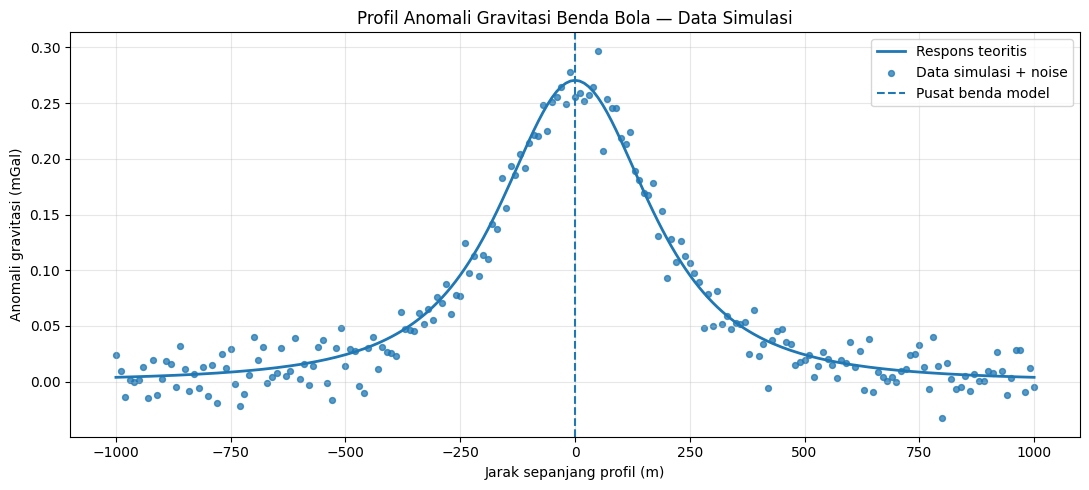

In [4]:
plt.figure(figsize=(11, 5))
plt.plot(x, g_theory_mgal, label="Respons teoritis", linewidth=2)
plt.scatter(x, g_observed, label="Data simulasi + noise", s=18, alpha=0.75)
plt.axvline(x0, linestyle="--", label="Pusat benda model")
plt.xlabel("Jarak sepanjang profil (m)")
plt.ylabel("Anomali gravitasi (mGal)")
plt.title("Profil Anomali Gravitasi Benda Bola — Data Simulasi")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Menaksir posisi puncak

Indeks data dengan nilai terbesar diambil sebagai perkiraan awal posisi horizontal benda. Cara ini sederhana dan sensitif terhadap noise, sehingga hasilnya tidak dianggap sebagai inversi atau penentuan posisi yang pasti.

In [5]:
peak_idx = int(np.argmax(g_observed))
estimated_x0 = float(x[peak_idx])
peak_value = float(g_observed[peak_idx])

print("=== RINGKASAN ESTIMASI ===")
print(f"Posisi pusat model sebenarnya : {x0:.1f} m")
print(f"Posisi maksimum data simulasi : {estimated_x0:.1f} m")
print(f"Anomali maksimum simulasi     : {peak_value:.4f} mGal")
print("\nCatatan: posisi maksimum adalah estimasi awal, bukan hasil inversi.")

=== RINGKASAN ESTIMASI ===
Posisi pusat model sebenarnya : 0.0 m
Posisi maksimum data simulasi : 50.0 m
Anomali maksimum simulasi     : 0.2971 mGal

Catatan: posisi maksimum adalah estimasi awal, bukan hasil inversi.


## 9. Menandai puncak pada kurva

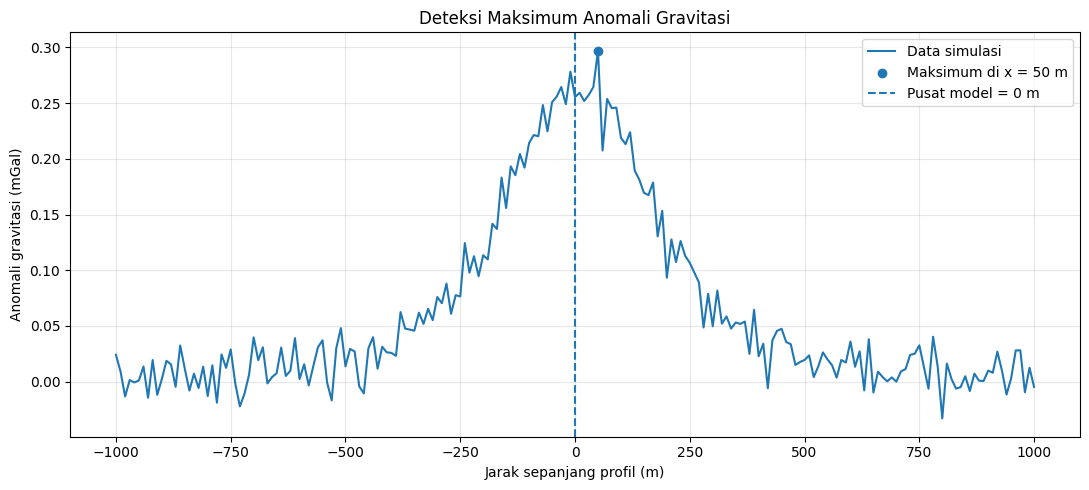

In [6]:
plt.figure(figsize=(11, 5))
plt.plot(x, g_observed, label="Data simulasi", linewidth=1.5)
plt.scatter([estimated_x0], [peak_value], zorder=3, label=f"Maksimum di x = {estimated_x0:.0f} m")
plt.axvline(x0, linestyle="--", label=f"Pusat model = {x0:.0f} m")
plt.xlabel("Jarak sepanjang profil (m)")
plt.ylabel("Anomali gravitasi (mGal)")
plt.title("Deteksi Maksimum Anomali Gravitasi")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 10. Menyimpan hasil ke CSV

In [7]:
profile = pd.DataFrame({
    "distance_m": x,
    "gravity_theory_mGal": g_theory_mgal,
    "gravity_simulated_mGal": g_observed
})
profile.to_csv("profil_anomali_gravitasi.csv", index=False)

summary = pd.DataFrame([{
    "data_type": "simulasi",
    "radius_m": radius,
    "depth_center_m": depth,
    "density_contrast_kg_m3": density_contrast,
    "true_center_x_m": x0,
    "estimated_peak_x_m": estimated_x0,
    "peak_anomaly_mGal": peak_value
}])
summary.to_csv("ringkasan_model_gravitasi.csv", index=False)

print("File tersimpan:")
print("- profil_anomali_gravitasi.csv")
print("- ringkasan_model_gravitasi.csv")
display(summary)

File tersimpan:
- profil_anomali_gravitasi.csv
- ringkasan_model_gravitasi.csv


,data_type,radius_m,depth_center_m,density_contrast_kg_m3,true_center_x_m,estimated_peak_x_m,peak_anomaly_mGal
0,simulasi,120.0,250.0,350.0,0.0,50.0,0.297106


## 11. Membaca hasil

Jalankan sel di bawah untuk melihat angka yang benar-benar dihasilkan oleh parameter dan noise pada percobaan ini. Perhatikan selisih antara pusat model dan lokasi puncak data. Jika ada selisih, salah satu penyebabnya adalah noise dan jarak antar titik pengukuran.

Hasil tetap harus dibaca sebagai simulasi. Model sederhana ini belum memperhitungkan bentuk geologi yang tidak beraturan, beberapa benda sekaligus, maupun ketidakpastian parameter.

In [8]:
offset = abs(estimated_x0 - x0)
print('HASIL PERCOBAAN')
print(f'Pusat benda pada model       : {x0:.1f} m')
print(f'Posisi puncak data simulasi  : {estimated_x0:.1f} m')
print(f'Selisih posisi               : {offset:.1f} m')
print(f'Anomali teoritis maksimum    : {g_theory_mgal.max():.4f} mGal')
print(f'Anomali maksimum data/noise  : {peak_value:.4f} mGal')
print('Catatan: angka di atas berasal dari simulasi, bukan pengukuran lapangan.')

HASIL PERCOBAAN
Pusat benda pada model       : 0.0 m
Posisi puncak data simulasi  : 50.0 m
Selisih posisi               : 50.0 m
Anomali teoritis maksimum    : 0.2705 mGal
Anomali maksimum data/noise  : 0.2971 mGal
Catatan: angka di atas berasal dari simulasi, bukan pengukuran lapangan.


## 12. Percobaan tambahan: pengaruh kedalaman

Pada bagian ini, parameter lain dipertahankan dan kedalaman pusat benda diubah. Bandingkan tinggi serta lebar kurva. Ini membantu menunjukkan bahwa kedalaman memengaruhi bentuk respons gravitasi.

## 13. Kesimpulan

Tuliskan kesimpulan berdasarkan angka dan grafik yang muncul setelah notebook dijalankan. Pastikan menyebutkan bahwa data bersifat sintetis, membandingkan posisi puncak dengan posisi pusat model, dan menjelaskan perubahan kurva saat kedalaman diubah.

**Catatan pemeriksaan:** bila mengubah parameter, jalankan kembali sel-sel setelah perubahan agar grafik dan ringkasan memakai nilai yang sama.

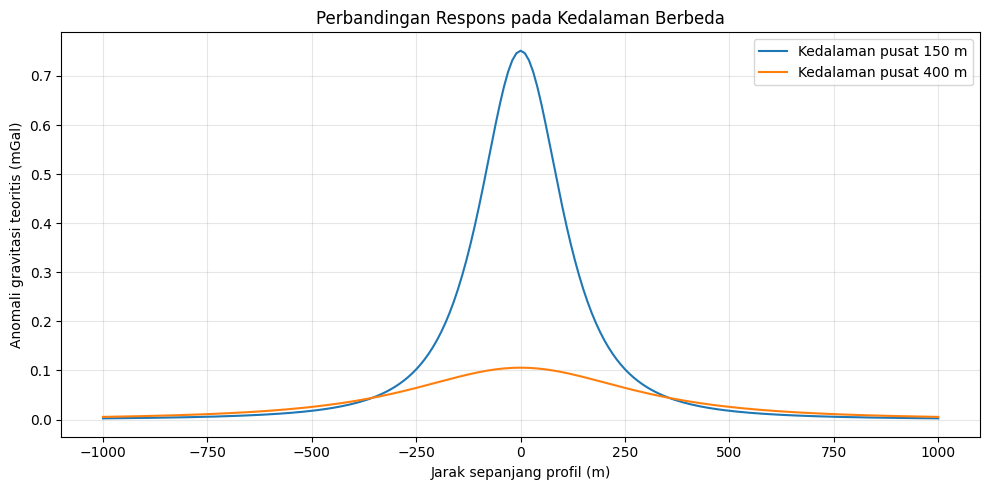

Bandingkan tinggi puncak dan lebar kurva pada kedua kedalaman.
Pada model ini, benda yang lebih dalam umumnya menghasilkan puncak lebih rendah dan kurva lebih lebar.


In [9]:
# Bandingkan respons untuk dua kedalaman; parameter lain tetap sama
G = 6.67430e-11
radius_compare = radius
density_compare = density_contrast
x0_compare = x0
depths = [150.0, 400.0]

plt.figure(figsize=(10, 5))
for z_compare in depths:
    mass_compare = (4.0 / 3.0) * np.pi * radius_compare**3 * density_compare
    r2_compare = (x - x0_compare)**2 + z_compare**2
    g_compare = G * mass_compare * z_compare / (r2_compare**1.5) * 1e5
    plt.plot(x, g_compare, label=f'Kedalaman pusat {z_compare:.0f} m')

plt.xlabel('Jarak sepanjang profil (m)')
plt.ylabel('Anomali gravitasi teoritis (mGal)')
plt.title('Perbandingan Respons pada Kedalaman Berbeda')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print('Bandingkan tinggi puncak dan lebar kurva pada kedua kedalaman.')
print('Pada model ini, benda yang lebih dalam umumnya menghasilkan puncak lebih rendah dan kurva lebih lebar.')